Global config loaded.
N_SOURCES           : 3
BASE_VALUE_M        : 0.1500 m
USE_FIXED_CENTER_HZ : True
FIXED_CENTER_HZ     : 1100.0 Hz
center frequency Hz: 1100.00
raw source length: (48000,)
band source length: (48000,)


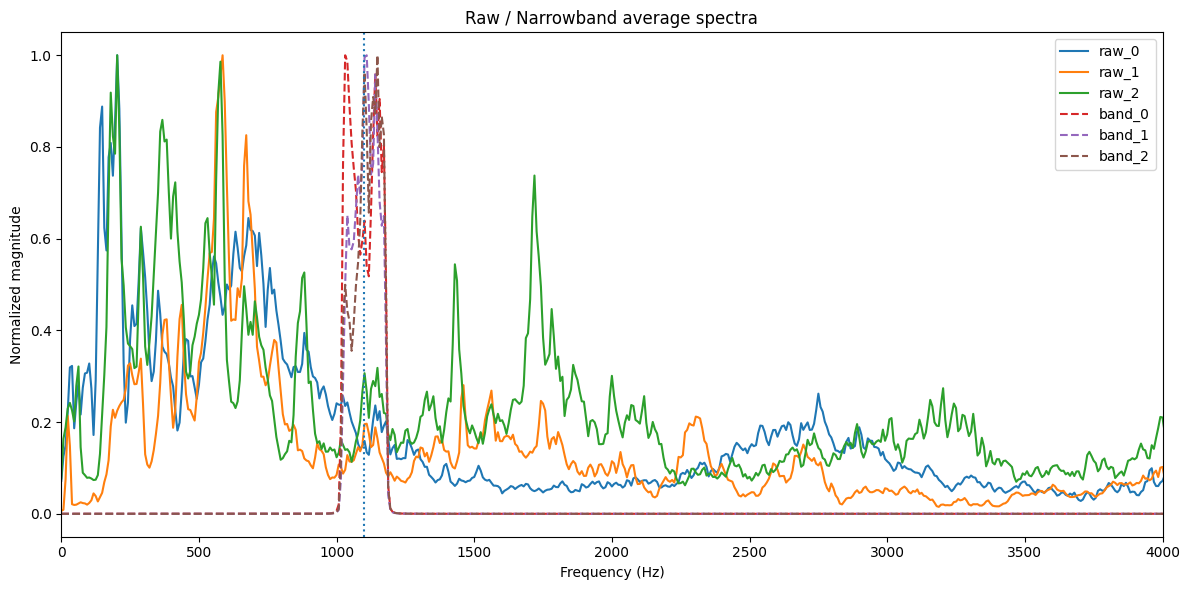

source positions:
  src0: [ 2.7291793  -1.5756924   0.94432583]
  src1: [3.  0.  1.5]
  src2: [2.38803189 1.37873085 1.9862149 ]

[Linear]
spacing: 0.15
mic shape: (3, 6)
estimated azimuths: [-31.75   1.    30.25]
azimuth RMSE: 1.1726039399558574


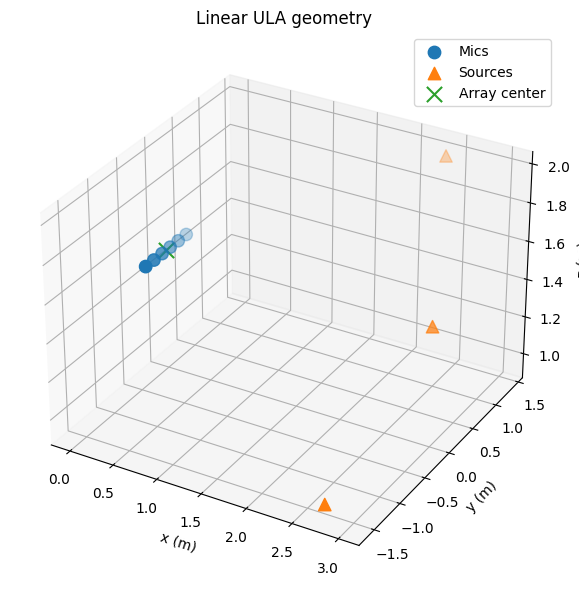

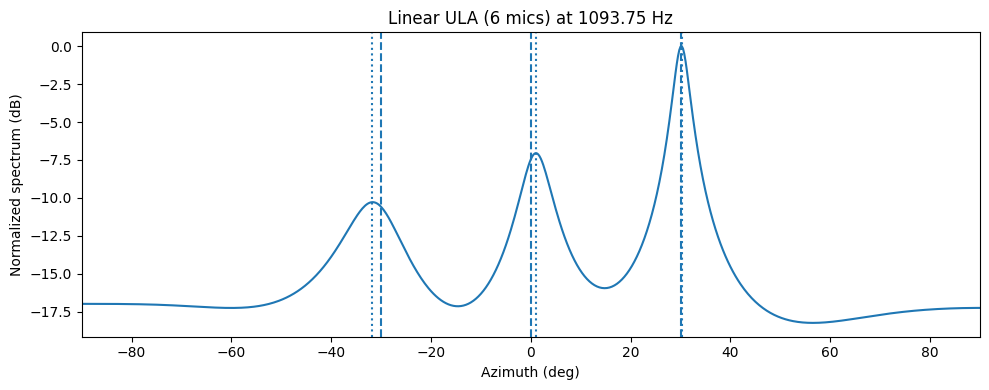

[[ 0.     0.     0.     0.     0.     0.   ]
 [-0.075  0.075 -0.075  0.075 -0.075  0.075]
 [ 1.35   1.35   1.5    1.5    1.65   1.65 ]]

[Planar]
spacing: (0.15, 0.15)
mic shape: (3, 6)
estimated (az, el): [(-10.5, -1.0, 0.9059028652464948), (-7.5, 0.0, 0.9900563635651334), (-4.5, 1.0, 0.9999999999999837)]
azimuth RMSE: 23.286262044390035
elevation RMSE: 7.3484692283495345


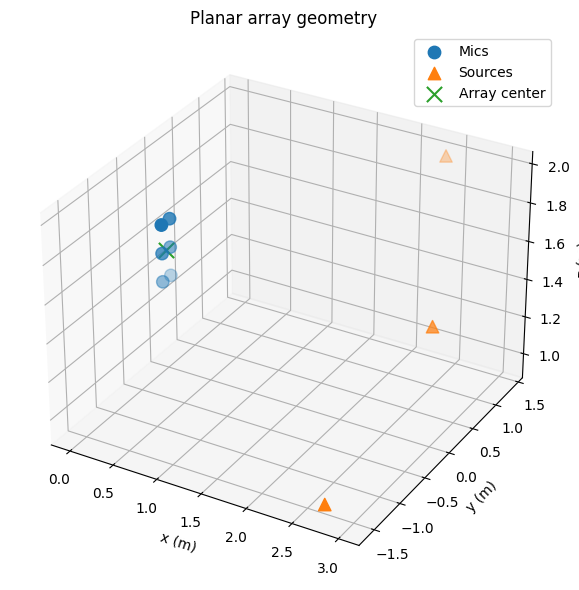

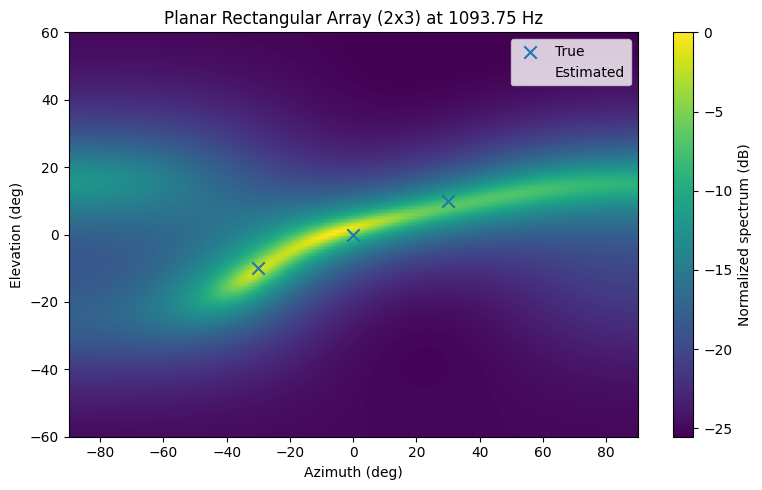

[[ 0.     0.     0.     0.     0.     0.   ]
 [-0.075  0.075 -0.075  0.075 -0.075  0.075]
 [ 1.35   1.35   1.5    1.5    1.65   1.65 ]]

[Sparse]
estimated (az, el): [(-33.0, -21.0, 0.9268227507262653), (68.0, 23.0, 0.6680207535753074), (70.25, 24.0, 1.0)]
azimuth RMSE: 45.65472775810482
elevation RMSE: 16.792855623746664


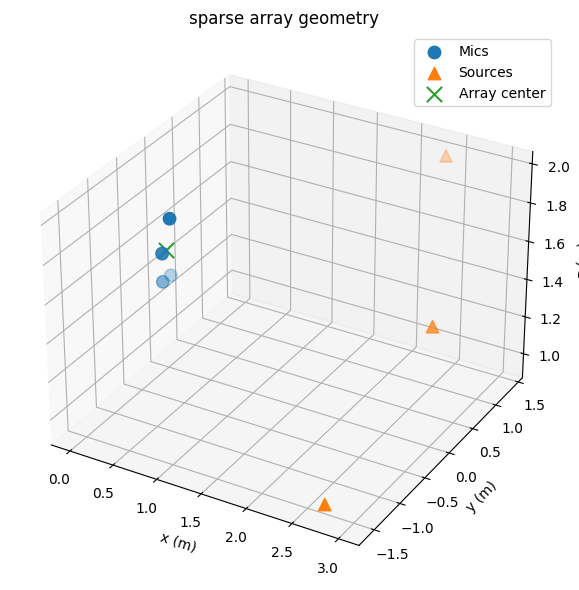

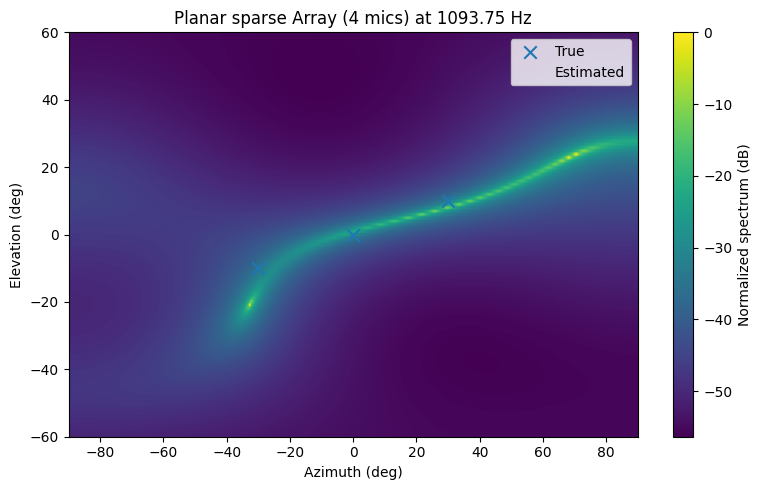


==================== SUMMARY ====================
Linear est az      : [-31.75   1.    30.25]
Planar est az/el   : [(-10.5, -1.0, 0.9059028652464948), (-7.5, 0.0, 0.9900563635651334), (-4.5, 1.0, 0.9999999999999837)]
Planar sparse est az/el   : [(-33.0, -21.0, 0.9268227507262653), (68.0, 23.0, 0.6680207535753074), (70.25, 24.0, 1.0)]


In [15]:
# ============================================================
# Compare Linear / Planar / Planar Sparse Arrays with MUSIC
# - Linear ULA      : 1D MUSIC (azimuth only)
# - Planar Array    : 2D MUSIC (azimuth + elevation)
# - Planar Sparse Array     : 2D MUSIC (azimuth + elevation)
# ============================================================

import math
import random
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt

from scipy.signal import stft, resample_poly, find_peaks
from scipy.fft import rfft, irfft, rfftfreq
from scipy.ndimage import maximum_filter
import pyroomacoustics as pra

np.random.seed(42)
random.seed(42)

# ------------------------------------------------------------
# Global config
# ------------------------------------------------------------
FS = 16000
C = 343.0
DURATION_SEC = 3.0

LIBRISPEECH_FILES = [
    "C:/26'음향학회 춘계학술대회/male26.flac",
    "C:/26'음향학회 춘계학술대회/female19.flac",
    "C:/26'음향학회 춘계학술대회/female8975.flac",
]

N_SOURCES = 3

SOURCE_AZIMUTH_DEG = np.array([-30.0, 0.0, 30.0], dtype=np.float64)
SOURCE_ELEVATION_DEG = np.array([-10.0, 0.0, 10.0], dtype=np.float64)
SOURCE_DISTANCES_M = np.array([3.2, 3.0, 2.8], dtype=np.float64)

ARRAY_CENTER = np.array([0.0, 0.0, 1.5], dtype=np.float64)

# compare spacing
# 실험 초반에는 aliasing을 줄이기 위해 너무 크게 잡지 않는 것이 좋음
BASE_VALUE_M = 0.15

USE_FIXED_CENTER_HZ = True
FIXED_CENTER_HZ = 1100.0

SEARCH_FMIN_HZ = 300.0
SEARCH_FMAX_HZ = 3400.0
BANDWIDTH_HZ = 150.0

STFT_NFFT = 1024
STFT_HOP = 256

AZ_GRID_DEG = np.linspace(-90.0, 90.0, 721)   # 0.25 deg
EL_GRID_DEG = np.linspace(-60.0, 60.0, 121)   # 1 deg

PLOT_RAW_AND_BAND_SPECTRA = True
PLOT_MIC_SIGNALS = False
PLOT_LINEAR_MUSIC = True
PLOT_PLANAR_MUSIC = True
PLOT_SPARSE_MUSIC = True

assert len(LIBRISPEECH_FILES) == N_SOURCES
assert len(SOURCE_AZIMUTH_DEG) == N_SOURCES
assert len(SOURCE_ELEVATION_DEG) == N_SOURCES
assert len(SOURCE_DISTANCES_M) == N_SOURCES

print("Global config loaded.")
print(f"N_SOURCES           : {N_SOURCES}")
print(f"BASE_VALUE_M        : {BASE_VALUE_M:.4f} m")
print(f"USE_FIXED_CENTER_HZ : {USE_FIXED_CENTER_HZ}")
if USE_FIXED_CENTER_HZ:
    print(f"FIXED_CENTER_HZ     : {FIXED_CENTER_HZ:.1f} Hz")


# ============================================================
# Audio helpers
# ============================================================
def read_audio_mono_resample(path: str, target_fs: int) -> np.ndarray:
    x, fs = sf.read(path)

    if x.ndim > 1:
        x = np.mean(x, axis=1)

    x = x.astype(np.float64)

    if fs != target_fs:
        print(f"[INFO] resampling {path}: {fs} -> {target_fs}")
        g = math.gcd(fs, target_fs)
        up = target_fs // g
        down = fs // g
        x = resample_poly(x, up, down)

    x = x - np.mean(x)
    # x = x / (np.max(np.abs(x)) + 1e-12)
    return x


def center_crop_or_pad(x: np.ndarray, target_len: int) -> np.ndarray:
    if len(x) >= target_len:
        start = (len(x) - target_len) // 2
        return x[start:start + target_len].copy()

    print("[INFO] audio shorter than target, zero padding...")
    y = np.zeros(target_len, dtype=np.float64)
    y[:len(x)] = x
    return y


def average_speech_spectrum(
    x: np.ndarray,
    fs: int,
    n_fft: int = 2048,
    hop: int = 512
) -> tuple[np.ndarray, np.ndarray]:
    f, _, Z = stft(
        x,
        fs=fs,
        window="hann",
        nperseg=n_fft,
        noverlap=n_fft - hop,
        boundary=None,
        padded=False,
    )

    mag = np.abs(Z)
    frame_energy = np.mean(mag ** 2, axis=0)

    thr = np.percentile(frame_energy, 10.0)
    valid = frame_energy > thr
    if not np.any(valid):
        valid = np.ones_like(frame_energy, dtype=bool)

    avg_mag = np.mean(mag[:, valid], axis=1)
    return f, avg_mag


def choose_common_dominant_band(
    signals: list[np.ndarray],
    fs: int,
    fmin_hz: float,
    fmax_hz: float,
) -> float:
    stacked = None
    freqs = None

    for x in signals:
        f, avg_mag = average_speech_spectrum(x, fs=fs)
        avg_mag = avg_mag / (np.max(avg_mag) + 1e-12)

        if stacked is None:
            stacked = avg_mag
            freqs = f
        else:
            stacked += avg_mag

    mask = (freqs >= fmin_hz) & (freqs <= fmax_hz)
    if not np.any(mask):
        raise ValueError("No FFT bins inside search range.")

    f_sel = freqs[mask]
    a_sel = stacked[mask]
    center_hz = f_sel[np.argmax(a_sel)]
    return float(center_hz)


def get_center_frequency(signals: list[np.ndarray]) -> float:
    if USE_FIXED_CENTER_HZ:
        return float(FIXED_CENTER_HZ)

    return choose_common_dominant_band(
        signals=signals,
        fs=FS,
        fmin_hz=SEARCH_FMIN_HZ,
        fmax_hz=SEARCH_FMAX_HZ,
    )


def fft_keep_only_band(
    x: np.ndarray,
    fs: int,
    center_hz: float,
    bandwidth_hz: float
) -> np.ndarray:
    n = len(x)
    X = rfft(x)
    f = rfftfreq(n, d=1.0 / fs)

    half_bw = bandwidth_hz / 2.0
    mask = (f >= center_hz - half_bw) & (f <= center_hz + half_bw)

    Y = np.zeros_like(X)
    Y[mask] = X[mask]
    y = irfft(Y, n=n)

    y = y - np.mean(y)
    # y = y / (np.max(np.abs(y)) + 1e-12)
    return y.astype(np.float64)


def prepare_narrowband_sources(
    file_paths: list[str],
    duration_sec: float,
) -> tuple[list[np.ndarray], list[np.ndarray], float]:
    target_len = int(FS * duration_sec)

    raw_sources = []
    for path in file_paths:
        x = read_audio_mono_resample(path, FS)
        x = center_crop_or_pad(x, target_len)
        raw_sources.append(x)

    center_hz = get_center_frequency(raw_sources)

    narrow_sources = [
        fft_keep_only_band(
            x,
            fs=FS,
            center_hz=center_hz,
            bandwidth_hz=BANDWIDTH_HZ
        )
        for x in raw_sources
    ]

    return raw_sources, narrow_sources, center_hz


def plot_raw_and_band_spectra(
    raw_sources: list[np.ndarray],
    narrow_sources: list[np.ndarray],
    fs: int,
    center_hz: float,
):
    if not PLOT_RAW_AND_BAND_SPECTRA:
        return

    plt.figure(figsize=(12, 6))

    for i, x in enumerate(raw_sources):
        f, avg_mag = average_speech_spectrum(x, fs)
        avg_mag = avg_mag / (np.max(avg_mag) + 1e-12)
        plt.plot(f, avg_mag, label=f"raw_{i}")

    for i, x in enumerate(narrow_sources):
        f, avg_mag = average_speech_spectrum(x, fs)
        avg_mag = avg_mag / (np.max(avg_mag) + 1e-12)
        plt.plot(f, avg_mag, linestyle="--", label=f"band_{i}")

    plt.axvline(center_hz, linestyle=":")
    plt.title("Raw / Narrowband average spectra")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Normalized magnitude")
    plt.xlim(0, 4000)
    plt.legend()
    plt.tight_layout()
    plt.show()


# ============================================================
# Geometry / source helpers
# ============================================================
def sph_to_cart(
    center_xyz: np.ndarray,
    az_deg: float,
    el_deg: float,
    r: float,
) -> np.ndarray:
    az = np.deg2rad(az_deg)
    el = np.deg2rad(el_deg)

    x = center_xyz[0] + r * np.cos(el) * np.cos(az)
    y = center_xyz[1] + r * np.cos(el) * np.sin(az)
    z = center_xyz[2] + r * np.sin(el)

    return np.array([x, y, z], dtype=np.float64)


def build_source_positions() -> list[np.ndarray]:
    positions = []
    for az_deg, el_deg, dist_m in zip(
        SOURCE_AZIMUTH_DEG,
        SOURCE_ELEVATION_DEG,
        SOURCE_DISTANCES_M,
    ):
        positions.append(
            sph_to_cart(
                center_xyz=ARRAY_CENTER,
                az_deg=az_deg,
                el_deg=el_deg,
                r=dist_m,
            )
        )
    return positions


# ============================================================
# STFT / covariance helpers
# ============================================================
def multichannel_stft(
    y_mics: np.ndarray,
    fs: int,
    n_fft: int,
    hop: int,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    Z_all = []
    f_ref = None
    t_ref = None

    for m in range(y_mics.shape[0]):
        f, t, Z = stft(
            y_mics[m],
            fs=fs,
            window="hann",
            nperseg=n_fft,
            noverlap=n_fft - hop,
            boundary=None,
            padded=False,
        )
        Z_all.append(Z)

        if f_ref is None:
            f_ref = f
            t_ref = t

    Z_all = np.stack(Z_all, axis=0)  # M x F x T
    return f_ref, t_ref, Z_all


def extract_frequency_bin_snapshots(
    y_mics: np.ndarray,
    fs: int,
    target_hz: float,
    n_fft: int,
    hop: int,
) -> tuple[float, np.ndarray]:
    f, _, Z = multichannel_stft(y_mics, fs, n_fft=n_fft, hop=hop)
    k = int(np.argmin(np.abs(f - target_hz)))
    X_bin = Z[:, k, :]   # M x N_snapshots
    return float(f[k]), X_bin


def sample_covariance(X: np.ndarray) -> np.ndarray:
    return (X @ X.conj().T) / X.shape[1]


# ============================================================
# Simulation / metrics
# ============================================================
def simulate_array_signals(
    mic_locs: np.ndarray,              # shape (3, M)
    source_positions: list[np.ndarray],
    source_signals: list[np.ndarray],
    fs: int,
    snr_db: float = 0.0,
) -> np.ndarray:
    room = pra.AnechoicRoom(fs=fs, dim=3)
    room.add_microphone_array(mic_locs)

    for pos, sig in zip(source_positions, source_signals):
        room.add_source(pos, signal=sig)

    room.simulate(snr=snr_db)
    return room.mic_array.signals      # shape (M, T)


def azimuth_rmse_deg(true_az_deg: np.ndarray, est_az_deg: np.ndarray) -> float:
    true_az = np.sort(np.asarray(true_az_deg, dtype=np.float64))
    est_az = np.sort(np.asarray(est_az_deg, dtype=np.float64))

    if len(true_az) != len(est_az):
        raise ValueError(f"RMSE source count mismatch: true={len(true_az)}, est={len(est_az)}")

    return float(np.sqrt(np.mean((est_az - true_az) ** 2)))


def az_el_rmse_deg(
    true_az_deg: np.ndarray,
    true_el_deg: np.ndarray,
    est_az_deg: np.ndarray,
    est_el_deg: np.ndarray,
) -> tuple[float, float]:
    if not (
        len(true_az_deg) == len(true_el_deg) ==
        len(est_az_deg) == len(est_el_deg)
    ):
        raise ValueError("RMSE source count mismatch")

    true_pairs = np.array(
        sorted(zip(true_az_deg, true_el_deg), key=lambda x: x[0]),
        dtype=np.float64
    )
    est_pairs = np.array(
        sorted(zip(est_az_deg, est_el_deg), key=lambda x: x[0]),
        dtype=np.float64
    )

    az_rmse = float(np.sqrt(np.mean((true_pairs[:, 0] - est_pairs[:, 0]) ** 2)))
    el_rmse = float(np.sqrt(np.mean((true_pairs[:, 1] - est_pairs[:, 1]) ** 2)))
    return az_rmse, el_rmse


# ============================================================
# Array builders
# ============================================================
def build_linear_array(
    center_xyz: np.ndarray,
    spacing_m: float,
    n_mics: int = 6,
) -> tuple[np.ndarray, float]:
    offsets = np.arange(n_mics, dtype=np.float64) * spacing_m
    offsets = offsets - np.mean(offsets)

    x = np.full(n_mics, center_xyz[0], dtype=np.float64)
    y = center_xyz[1] + offsets
    z = np.full(n_mics, center_xyz[2], dtype=np.float64)

    mic_locs = np.vstack([x, y, z])
    return mic_locs, spacing_m


def build_planar_rect_array(
    center_xyz: np.ndarray,
    ny: int = 2,
    nz: int = 3,
    spacing_y_m: float = 0.06,
    spacing_z_m: float = 0.06,
) -> tuple[np.ndarray, tuple[float, float]]:
    ys = (np.arange(ny) - (ny - 1) / 2.0) * spacing_y_m
    zs = (np.arange(nz) - (nz - 1) / 2.0) * spacing_z_m

    yv, zv = np.meshgrid(ys, zs, indexing="xy")
    yv = yv.ravel()
    zv = zv.ravel()
    xv = np.zeros_like(yv)

    mic_locs = np.vstack([
        center_xyz[0] + xv,   # x 고정
        center_xyz[1] + yv,   # y 방향으로 배치
        center_xyz[2] + zv,   # z 방향으로 배치
    ])
    print(mic_locs)
    return mic_locs, (spacing_y_m, spacing_z_m)


def build_sparse_array(
    center_xyz: np.ndarray,
    spacing_y_m: float = 0.06,
    spacing_z_m: float = 0.06,
) -> tuple[np.ndarray, tuple[float, float]]:
    planar_mics, _ = build_planar_rect_array(
        center_xyz=center_xyz,
        ny=2,
        nz=3,
        spacing_y_m=spacing_y_m,
        spacing_z_m=spacing_z_m,
    )

    # 1, 2, 3, 6번 선택 -> Python index [0, 1, 2, 5]
    selected_idx = [0, 1, 2, 5]
    mic_locs = planar_mics[:, selected_idx]

    return mic_locs, (spacing_y_m, spacing_z_m)


# ============================================================
# Steering vectors
# ============================================================
def steering_vector_linear_azimuth(
    mic_positions_xyz: np.ndarray,
    array_center_xyz: np.ndarray,
    freq_hz: float,
    az_deg: float,
    c: float = 343.0,
) -> np.ndarray:
    az = np.deg2rad(az_deg)
    y_rel = mic_positions_xyz[1, :] - array_center_xyz[1]
    phase = 2.0j * np.pi * freq_hz / c * y_rel * np.sin(az)
    return np.exp(phase)[:, None]


def unit_direction_from_az_el(az_deg: float, el_deg: float) -> np.ndarray:
    az = np.deg2rad(az_deg)
    el = np.deg2rad(el_deg)

    ux = np.cos(el) * np.cos(az)
    uy = np.cos(el) * np.sin(az)
    uz = np.sin(el)

    return np.array([ux, uy, uz], dtype=np.float64)


def steering_vector_3d_farfield(
    mic_positions_xyz: np.ndarray,
    array_center_xyz: np.ndarray,
    freq_hz: float,
    az_deg: float,
    el_deg: float,
    c: float = 343.0,
) -> np.ndarray:
    rel = mic_positions_xyz - array_center_xyz[:, None]  # (3, M)
    u = unit_direction_from_az_el(az_deg, el_deg)        # (3,)
    proj = rel.T @ u                                     # (M,)

    phase = -2.0j * np.pi * freq_hz / c * proj
    return np.exp(phase)[:, None]


# ============================================================
# MUSIC: Linear 1D
# ============================================================
def music_spectrum_linear_1d(
    R: np.ndarray,
    mic_positions_xyz: np.ndarray,
    array_center_xyz: np.ndarray,
    freq_hz: float,
    n_sources: int,
    az_grid_deg: np.ndarray,
    c: float = 343.0,
) -> np.ndarray:
    eigvals, eigvecs = np.linalg.eigh(R)
    order = np.argsort(eigvals)[::-1]
    eigvecs = eigvecs[:, order]
    En = eigvecs[:, n_sources:]

    P = np.zeros(len(az_grid_deg), dtype=np.float64)

    for i, az in enumerate(az_grid_deg):
        a = steering_vector_linear_azimuth(
            mic_positions_xyz=mic_positions_xyz,
            array_center_xyz=array_center_xyz,
            freq_hz=freq_hz,
            az_deg=az,
            c=c,
        )
        denom = (a.conj().T @ En @ En.conj().T @ a).squeeze()
        P[i] = 1.0 / (np.abs(denom) + 1e-12)

    P = P / (np.max(P) + 1e-12)
    return P


def estimate_music_peaks_1d(
    P: np.ndarray,
    az_grid_deg: np.ndarray,
    n_sources: int,
    min_peak_distance_deg: float = 5.0,
) -> list[tuple[float, float]]:
    step_deg = float(np.abs(az_grid_deg[1] - az_grid_deg[0]))
    min_distance_bins = max(1, int(min_peak_distance_deg / step_deg))

    peaks, _ = find_peaks(P, distance=min_distance_bins)
    if len(peaks) == 0:
        return []

    peak_vals = P[peaks]
    order = np.argsort(peak_vals)[::-1]
    chosen = peaks[order[:n_sources]]

    results = [(float(az_grid_deg[i]), float(P[i])) for i in chosen]
    results.sort(key=lambda x: x[0])
    return results


# ============================================================
# MUSIC: General 2D
# ============================================================
def music_spectrum_2d(
    R: np.ndarray,
    mic_positions_xyz: np.ndarray,
    array_center_xyz: np.ndarray,
    freq_hz: float,
    n_sources: int,
    az_grid_deg: np.ndarray,
    el_grid_deg: np.ndarray,
    c: float = 343.0,
) -> np.ndarray:
    eigvals, eigvecs = np.linalg.eigh(R)
    order = np.argsort(eigvals)[::-1]
    eigvecs = eigvecs[:, order]
    En = eigvecs[:, n_sources:]

    P = np.zeros((len(el_grid_deg), len(az_grid_deg)), dtype=np.float64)

    for ie, el in enumerate(el_grid_deg):
        for ia, az in enumerate(az_grid_deg):
            a = steering_vector_3d_farfield(
                mic_positions_xyz=mic_positions_xyz,
                array_center_xyz=array_center_xyz,
                freq_hz=freq_hz,
                az_deg=az,
                el_deg=el,
                c=c,
            )
            denom = (a.conj().T @ En @ En.conj().T @ a).squeeze()
            P[ie, ia] = 1.0 / (np.abs(denom) + 1e-12)

    P = P / (np.max(P) + 1e-12)
    return P


def estimate_music_peaks_2d(
    P: np.ndarray,
    az_grid_deg: np.ndarray,
    el_grid_deg: np.ndarray,
    n_sources: int,
    neighborhood_size: int = 7,
    min_rel_level: float = 0.2,
) -> list[tuple[float, float, float]]:
    Pmax = maximum_filter(P, size=neighborhood_size, mode="nearest")
    peak_mask = (P == Pmax) & (P >= min_rel_level * np.max(P))

    peak_idx = np.argwhere(peak_mask)
    if len(peak_idx) == 0:
        return []

    peaks = []
    for ie, ia in peak_idx:
        peaks.append(
            (float(az_grid_deg[ia]), float(el_grid_deg[ie]), float(P[ie, ia]))
        )

    peaks.sort(key=lambda x: x[2], reverse=True)
    peaks = peaks[:n_sources]
    peaks.sort(key=lambda x: x[0])
    return peaks


# ============================================================
# Pipelines
# ============================================================
def run_linear_music_pipeline(
    mic_locs: np.ndarray,
    source_positions: list[np.ndarray],
    source_signals: list[np.ndarray],
    center_hz: float,
) -> dict:
    y_mics = simulate_array_signals(
        mic_locs=mic_locs,
        source_positions=source_positions,
        source_signals=source_signals,
        fs=FS,
        snr_db=-25.0,
    )

    chosen_bin_hz, X_bin = extract_frequency_bin_snapshots(
        y_mics=y_mics,
        fs=FS,
        target_hz=center_hz,
        n_fft=STFT_NFFT,
        hop=STFT_HOP,
    )

    R = sample_covariance(X_bin)

    P = music_spectrum_linear_1d(
        R=R,
        mic_positions_xyz=mic_locs,
        array_center_xyz=ARRAY_CENTER,
        freq_hz=chosen_bin_hz,
        n_sources=N_SOURCES,
        az_grid_deg=AZ_GRID_DEG,
        c=C,
    )

    peaks = estimate_music_peaks_1d(
        P=P,
        az_grid_deg=AZ_GRID_DEG,
        n_sources=N_SOURCES,
    )

    est_az_deg = np.array([p[0] for p in peaks], dtype=np.float64)

    return {
        "array_name": f"Linear ULA ({mic_locs.shape[1]} mics)",
        "mic_locs": mic_locs,
        "y_mics": y_mics,
        "chosen_bin_hz": chosen_bin_hz,
        "X_bin": X_bin,
        "R": R,
        "P": P,
        "peaks": peaks,
        "est_az_deg": est_az_deg,
    }


def run_music_pipeline_3d(
    mic_locs: np.ndarray,
    source_positions: list[np.ndarray],
    source_signals: list[np.ndarray],
    center_hz: float,
    array_name: str,
) -> dict:
    y_mics = simulate_array_signals(
        mic_locs=mic_locs,
        source_positions=source_positions,
        source_signals=source_signals,
        fs=FS,
        snr_db=-10.0,
    )

    chosen_bin_hz, X_bin = extract_frequency_bin_snapshots(
        y_mics=y_mics,
        fs=FS,
        target_hz=center_hz,
        n_fft=STFT_NFFT,
        hop=STFT_HOP,
    )

    R = sample_covariance(X_bin)

    P = music_spectrum_2d(
        R=R,
        mic_positions_xyz=mic_locs,
        array_center_xyz=ARRAY_CENTER,
        freq_hz=chosen_bin_hz,
        n_sources=N_SOURCES,
        az_grid_deg=AZ_GRID_DEG,
        el_grid_deg=EL_GRID_DEG,
        c=C,
    )

    peaks = estimate_music_peaks_2d(
        P=P,
        az_grid_deg=AZ_GRID_DEG,
        el_grid_deg=EL_GRID_DEG,
        n_sources=N_SOURCES,
    )

    est_az_deg = np.array([p[0] for p in peaks], dtype=np.float64)
    est_el_deg = np.array([p[1] for p in peaks], dtype=np.float64)

    return {
        "array_name": array_name,
        "mic_locs": mic_locs,
        "y_mics": y_mics,
        "chosen_bin_hz": chosen_bin_hz,
        "X_bin": X_bin,
        "R": R,
        "P": P,
        "peaks": peaks,
        "est_az_deg": est_az_deg,
        "est_el_deg": est_el_deg,
    }


# ============================================================
# Plot helpers
# ============================================================
def plot_mic_signals(y_mics: np.ndarray, title: str, max_samples: int = 3000):
    if not PLOT_MIC_SIGNALS:
        return

    plt.figure(figsize=(12, 6))
    for m in range(y_mics.shape[0]):
        plt.plot(y_mics[m, :max_samples] + 2.0 * m, label=f"mic{m}")
    plt.title(title)
    plt.xlabel("Sample")
    plt.ylabel("Amplitude (offset)")
    plt.tight_layout()
    plt.show()


def plot_array_geometry(
    mic_locs: np.ndarray,
    source_positions: list[np.ndarray],
    title: str,
):
    fig = plt.figure(figsize=(7, 6))
    ax = fig.add_subplot(111, projection="3d")

    ax.scatter(
        mic_locs[0, :], mic_locs[1, :], mic_locs[2, :],
        s=80, marker="o", label="Mics"
    )

    src = np.array(source_positions)
    ax.scatter(
        src[:, 0], src[:, 1], src[:, 2],
        s=80, marker="^", label="Sources"
    )

    ax.scatter(
        ARRAY_CENTER[0], ARRAY_CENTER[1], ARRAY_CENTER[2],
        s=120, marker="x", label="Array center"
    )

    ax.set_title(title)
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.set_zlabel("z (m)")
    ax.legend()
    plt.tight_layout()
    plt.show()


def plot_linear_music_1d(result: dict, true_az_deg: np.ndarray):
    plt.figure(figsize=(10, 4))
    plt.plot(
        AZ_GRID_DEG,
        10.0 * np.log10(result["P"] + 1e-12),
        label="Linear MUSIC",
    )

    for az in true_az_deg:
        plt.axvline(az, linestyle="--")

    for az, _ in result["peaks"]:
        plt.axvline(az, linestyle=":")

    plt.xlabel("Azimuth (deg)")
    plt.ylabel("Normalized spectrum (dB)")
    plt.title(f"{result['array_name']} at {result['chosen_bin_hz']:.2f} Hz")
    plt.xlim(AZ_GRID_DEG[0], AZ_GRID_DEG[-1])
    plt.tight_layout()
    plt.show()


def plot_music_2d(result: dict, true_az_deg: np.ndarray, true_el_deg: np.ndarray):
    P_db = 10.0 * np.log10(result["P"] + 1e-12)

    plt.figure(figsize=(8, 5))
    plt.imshow(
        P_db,
        aspect="auto",
        origin="lower",
        extent=[AZ_GRID_DEG[0], AZ_GRID_DEG[-1], EL_GRID_DEG[0], EL_GRID_DEG[-1]],
    )
    plt.colorbar(label="Normalized spectrum (dB)")
    plt.xlabel("Azimuth (deg)")
    plt.ylabel("Elevation (deg)")
    plt.title(f"{result['array_name']} at {result['chosen_bin_hz']:.2f} Hz")

    plt.scatter(true_az_deg, true_el_deg, marker="x", s=80, label="True")
    if len(result["peaks"]) > 0:
        est_az = [p[0] for p in result["peaks"]]
        est_el = [p[1] for p in result["peaks"]]
        plt.scatter(est_az, est_el, marker="o", s=60, facecolors="none", label="Estimated")

    plt.legend()
    plt.tight_layout()
    plt.show()


# ============================================================
# Main
# ============================================================
if __name__ == "__main__":
    raw_sources, narrow_sources, center_hz = prepare_narrowband_sources(
        LIBRISPEECH_FILES,
        DURATION_SEC,
    )

    print(f"center frequency Hz: {center_hz:.2f}")
    print("raw source length:", raw_sources[0].shape)
    print("band source length:", narrow_sources[0].shape)

    plot_raw_and_band_spectra(raw_sources, narrow_sources, FS, center_hz)

    source_positions = build_source_positions()
    print("source positions:")
    for i, p in enumerate(source_positions):
        print(f"  src{i}: {p}")

    # --------------------------------------------------------
    # 1) Linear array
    # --------------------------------------------------------
    linear_mics, linear_spacing = build_linear_array(
        center_xyz=ARRAY_CENTER,
        spacing_m=BASE_VALUE_M,
        n_mics=6,
    )

    print("\n[Linear]")
    print("spacing:", linear_spacing)
    print("mic shape:", linear_mics.shape)

    linear_result = run_linear_music_pipeline(
        mic_locs=linear_mics,
        source_positions=source_positions,
        source_signals=narrow_sources,
        center_hz=center_hz,
    )

    print("estimated azimuths:", linear_result["est_az_deg"])
    try:
        rmse_val = azimuth_rmse_deg(SOURCE_AZIMUTH_DEG, linear_result["est_az_deg"])
        print("azimuth RMSE:", rmse_val)
    except ValueError as e:
        print("azimuth RMSE: 계산 불가", e)

    plot_array_geometry(linear_mics, source_positions, "Linear ULA geometry")
    plot_mic_signals(linear_result["y_mics"], "Linear mic signals")

    if PLOT_LINEAR_MUSIC:
        plot_linear_music_1d(linear_result, SOURCE_AZIMUTH_DEG)

    # --------------------------------------------------------
    # 2) Planar array
    # --------------------------------------------------------
    planar_mics, planar_spacing = build_planar_rect_array(
        center_xyz=ARRAY_CENTER,
        ny=2,
        nz=3,
        spacing_y_m=BASE_VALUE_M,
        spacing_z_m=BASE_VALUE_M,
    )

    print("\n[Planar]")
    print("spacing:", planar_spacing)
    print("mic shape:", planar_mics.shape)

    planar_result = run_music_pipeline_3d(
        mic_locs=planar_mics,
        source_positions=source_positions,
        source_signals=narrow_sources,
        center_hz=center_hz,
        array_name="Planar Rectangular Array (2x3)",
    )

    print("estimated (az, el):", planar_result["peaks"])
    try:
        az_rmse, el_rmse = az_el_rmse_deg(
            SOURCE_AZIMUTH_DEG,
            SOURCE_ELEVATION_DEG,
            planar_result["est_az_deg"],
            planar_result["est_el_deg"],
        )
        print("azimuth RMSE:", az_rmse)
        print("elevation RMSE:", el_rmse)
    except ValueError as e:
        print("az/el RMSE: 계산 불가", e)

    plot_array_geometry(planar_mics, source_positions, "Planar array geometry")
    plot_mic_signals(planar_result["y_mics"], "Planar mic signals")

    if PLOT_PLANAR_MUSIC:
        plot_music_2d(planar_result, SOURCE_AZIMUTH_DEG, SOURCE_ELEVATION_DEG)

    # --------------------------------------------------------
    # 3) sparse array
    # --------------------------------------------------------
    sparse_mics, sparse_edge = build_sparse_array(
        center_xyz=ARRAY_CENTER,
        spacing_y_m=BASE_VALUE_M,
        spacing_z_m=BASE_VALUE_M,
    )

    print("\n[Sparse]")

    sparse_result = run_music_pipeline_3d(
        mic_locs=sparse_mics,
        source_positions=source_positions,
        source_signals=narrow_sources,
        center_hz=center_hz,
        array_name="Planar sparse Array (4 mics)",
    )

    print("estimated (az, el):", sparse_result["peaks"])
    try:
        az_rmse, el_rmse = az_el_rmse_deg(
            SOURCE_AZIMUTH_DEG,
            SOURCE_ELEVATION_DEG,
            sparse_result["est_az_deg"],
            sparse_result["est_el_deg"],
        )
        print("azimuth RMSE:", az_rmse)
        print("elevation RMSE:", el_rmse)
    except ValueError as e:
        print("az/el RMSE: 계산 불가", e)

    plot_array_geometry(sparse_mics, source_positions, "sparse array geometry")
    plot_mic_signals(sparse_result["y_mics"], "sparse mic signals")

    if PLOT_SPARSE_MUSIC:
        plot_music_2d(sparse_result, SOURCE_AZIMUTH_DEG, SOURCE_ELEVATION_DEG)

    # --------------------------------------------------------
    # Summary
    # --------------------------------------------------------
    print("\n==================== SUMMARY ====================")
    print("Linear est az      :", linear_result["est_az_deg"])
    print("Planar est az/el   :", planar_result["peaks"])
    print("Planar sparse est az/el   :", sparse_result["peaks"])
    print("=================================================")